# Notebook 03 — MRI Baseline Model
Trains a CNN on MRI brain tumor images only. Loads splits from notebook 01.
> **Prerequisites:** Run notebook 01 first.

## 1. Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

Mounted at /content/drive


## 2. Unzip MRI Dataset (Skip if Already Done)

In [2]:
import zipfile, os
if not os.path.exists("/content/mri_data/MRI/Training/No Tumor/Tr-no_1.jpg"):
    print("Unzipping...")
    with zipfile.ZipFile("/content/drive/MyDrive/MRI/MRI.zip", 'r') as z:
        z.extractall("/content/mri_data/")
    print("Done!")
else:
    print("Already unzipped, skipping.")

Unzipping...
Done!


## 3. Imports

In [3]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

IMG_SIZE   = (224, 224)
BATCH_SIZE = 16
EPOCHS     = 50

print("TensorFlow:", tf.__version__)
print("GPU:", len(tf.config.list_physical_devices('GPU')) > 0)

TensorFlow: 2.20.0
GPU: True


## 4. Load Splits from Notebook 01

In [4]:
data = np.load('/content/drive/MyDrive/MRI/mri_splits.npz', allow_pickle=True)
train_paths = data['train_paths']
val_paths   = data['val_paths']
test_paths  = data['test_paths']
y_train     = data['y_train']
y_val       = data['y_val']
y_test      = data['y_test']

print(f"Train: {len(train_paths)} | Val: {len(val_paths)} | Test: {len(test_paths)}")

Train: 120 | Val: 40 | Test: 40


## 5. Load All Images into Memory

In [5]:
def load_image(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, IMG_SIZE)
    return np.expand_dims(img / 255.0, axis=-1)

print("Loading images...")
X_train = np.array([load_image(p) for p in train_paths])
X_val   = np.array([load_image(p) for p in val_paths])
X_test  = np.array([load_image(p) for p in test_paths])

print(f"X_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}")

Loading images...
X_train: (120, 224, 224, 1) | X_val: (40, 224, 224, 1) | X_test: (40, 224, 224, 1)


## 6. Build MRI Baseline CNN

In [6]:
def build_mri_baseline():
    model = models.Sequential([
        layers.Input(shape=(224, 224, 1)),
        layers.Conv2D(32, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(128, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D(2, 2),
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(1, activation='sigmoid')
    ])
    return model

mri_model = build_mri_baseline()
mri_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)
mri_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,313 (427.00 KB)

 Trainable params: 109,313 (427.00 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Train

In [7]:
early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = mri_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop]
)

Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 13s 812ms/step - accuracy: 0.5500 - loss: 0.6928 - val_accuracy: 0.5000 - val_loss: 0.6920
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.5417 - loss: 0.6912 - val_accuracy: 0.5000 - val_loss: 0.6899
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.5000 - loss: 0.6899 - val_accuracy: 0.5000 - val_loss: 0.6883
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.5000 - loss: 0.6876 - val_accuracy: 0.5000 - val_loss: 0.6868
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.5000 - loss: 0.6860 - val_accuracy: 0.5000 - val_loss: 0.6844
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.5000 - loss: 0.6835 - val_accuracy: 0.5000 - val_loss: 0.6818
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.5000 - loss: 0.6822 - val_accuracy: 0.5000 - val_loss: 0.6788
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5000 - loss: 0.6804 - val_accuracy: 0.5000 - val_loss: 0.675

## 8. Training Curves

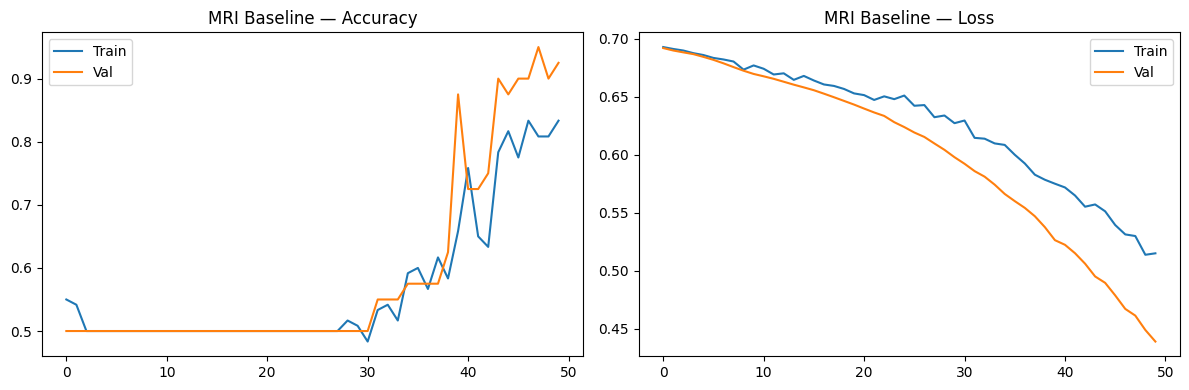

In [8]:
plt.figure(figsize=(12, 4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title('MRI Baseline — Accuracy')
plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title('MRI Baseline — Loss')
plt.legend()
plt.tight_layout()
plt.show()

## 9. Test Set Evaluation

In [9]:
test_probs = mri_model.predict(X_test, batch_size=BATCH_SIZE).flatten()
y_pred     = (test_probs > 0.5).astype(int)

print("--- MRI BASELINE: TEST SET RESULTS ---")
print(classification_report(y_test, y_pred, target_names=['Healthy', 'Tumor']))
print(f"ROC-AUC: {roc_auc_score(y_test, test_probs):.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 199ms/step
--- MRI BASELINE: TEST SET RESULTS ---
              precision    recall  f1-score   support

     Healthy       0.78      0.70      0.74        20
       Tumor       0.73      0.80      0.76        20

    accuracy                           0.75        40
   macro avg       0.75      0.75      0.75        40
weighted avg       0.75      0.75      0.75        40

ROC-AUC: 0.8200


## 10. Confusion Matrix

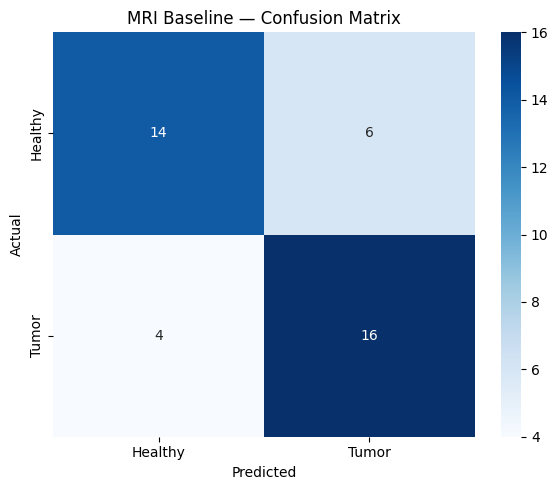

In [10]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Healthy','Tumor'], yticklabels=['Healthy','Tumor'])
plt.title('MRI Baseline — Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

## 11. Grad-CAM

Last conv layer: conv2d_2


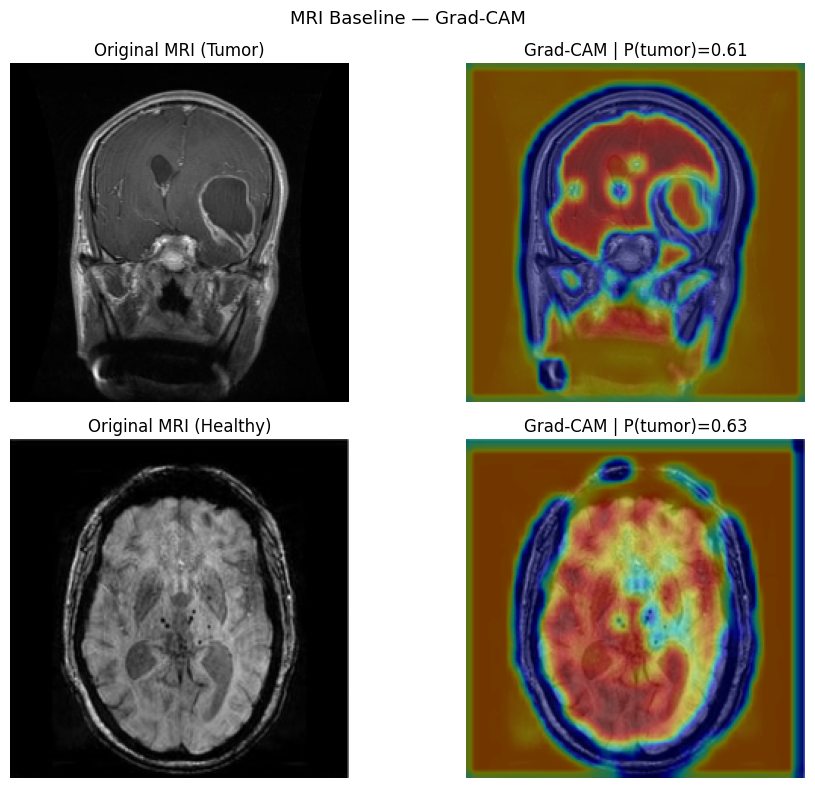

In [11]:
def make_gradcam_heatmap(model, img_array, last_conv_layer_name):
    inputs = tf.keras.Input(shape=(224, 224, 1))
    x = inputs
    conv_out = None
    for layer in model.layers:
        x = layer(x)
        if layer.name == last_conv_layer_name:
            conv_out = x
    grad_model = tf.keras.Model(inputs=inputs, outputs=[conv_out, x])
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        loss = predictions[:, 0]
    grads = tape.gradient(loss, conv_outputs)
    pooled = tf.reduce_mean(grads, axis=(0,1,2))
    heatmap = conv_outputs[0] @ pooled[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0)
    max_val = tf.reduce_max(heatmap)
    if max_val == 0:
        return np.zeros((224,224))
    return cv2.resize((heatmap/max_val).numpy(), (224,224))

last_conv = [l.name for l in mri_model.layers if isinstance(l, layers.Conv2D)][-1]
print("Last conv layer:", last_conv)

tumor_idx   = np.where(y_test == 1)[0][0]
healthy_idx = np.where(y_test == 0)[0][0]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for row, (idx, label) in enumerate([(tumor_idx,'Tumor'),(healthy_idx,'Healthy')]):
    img     = X_test[idx:idx+1]
    heatmap = make_gradcam_heatmap(mri_model, img, last_conv)
    prob    = test_probs[idx]
    axes[row,0].imshow(img[0].squeeze(), cmap='gray')
    axes[row,0].set_title(f"Original MRI ({label})")
    axes[row,0].axis('off')
    axes[row,1].imshow(img[0].squeeze(), cmap='gray')
    axes[row,1].imshow(heatmap, cmap='jet', alpha=0.45)
    axes[row,1].set_title(f"Grad-CAM | P(tumor)={prob:.2f}")
    axes[row,1].axis('off')
plt.suptitle('MRI Baseline — Grad-CAM', fontsize=13)
plt.tight_layout()
plt.show()

## 12. Save Model

In [12]:
mri_model.save("/content/drive/MyDrive/MRI/mri_baseline.keras")
print("Model saved!")

Model saved!
